# OISST: world sea surface temperature since 1981

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ocean-icechunks/2026-ioos-hackathon/blob/main/examples/04-oisst-world-sst.ipynb)

Rebuild the well-known [Climate Reanalyzer](https://climatereanalyzer.org/clim/sst_daily/) chart of
daily world sea surface temperature from NOAA's
[OISST v2.1](https://www.ncei.noaa.gov/products/optimum-interpolation-sst): the area-weighted mean
from 60 °S to 60 °N, one line per year.

The data are NOAA's daily files on AWS, **one NetCDF per day, about 16,500 of them**. The
[virtual Icechunk store](https://source.coop/ocean-icechunks/noaa-oisst), maintained by
NERACOOS / GMRI, makes them one dataset with one time axis, so the whole record is a single
`sel()` and `mean()`. No credentials needed.

In [ ]:
%pip install -q "icechunk>=2.3" "xarray>=2026.7" "zarr>=3.4" "dask[array]" matplotlib

## Open the dataset

The store's `daily/` group holds only references; every value is read by byte range from NOAA's
files in the `noaa-cdr-sea-surface-temp-optimum-interpolation-pds` bucket.

In [2]:
import time
import icechunk, xarray as xr, zarr
import numpy as np, matplotlib.pyplot as plt

zarr.config.set({"async.concurrency": 32})   # per dask thread; much higher can drop connections

url = "https://data.source.coop/ocean-icechunks/noaa-oisst/oisst.icechunk"
repo = icechunk.Repository.open(icechunk.http_storage(url))
# The data stay in NOAA's public S3 bucket: allow anonymous reads there.
auth = icechunk.containers_credentials(
    {p: icechunk.s3_anonymous_credentials() for p in repo.config.virtual_chunk_containers})
repo = repo.reopen(authorize_virtual_chunk_access=auth)
daily = xr.open_zarr(repo.readonly_session("main").store, group="daily",
                     consolidated=False, chunks=None)
daily

<xarray.Dataset> Size: 548GB
Dimensions:      (time: 16508, zlev: 1, lat: 720, lon: 1440)
Coordinates:
  * time         (time) datetime64[ns] 132kB 1981-09-01T12:00:00 ... 2026-11-...
    preliminary  (time) bool 17kB ...
  * zlev         (zlev) float32 4B 0.0
  * lat          (lat) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * lon          (lon) float32 6kB 0.125 0.375 0.625 0.875 ... 359.4 359.6 359.9
Data variables:
    anom         (time, zlev, lat, lon) float64 137GB ...
    err          (time, zlev, lat, lon) float64 137GB ...
    ice          (time, zlev, lat, lon) float64 137GB ...
    sst          (time, zlev, lat, lon) float64 137GB ...
Attributes: (12/38)
    title:                      NOAA/NCEI 1/4 Degree Daily Optimum Interpolat...
    source:                     ICOADS, NCEP_GTS, GSFC_ICE, NCEP_ICE, Pathfin...
    id:                         oisst-avhrr-v02r01.20261111_preliminary.nc
    naming_authority:           gov.noaa.ncei
    summary:                    NOAAs 1/4-degree Daily Optimum Interpolation ...
    cdm_data_type:              Grid
    ...                         ...
    ncei_template_version:      NCEI_NetCDF_Grid_Template_v2.0
    comment:                    Data was converted from NetCDF-3 to NetCDF-4 ...
    sensor:                     Thermometer, AVHRR
    Conventions:                CF-1.6, ACDD-1.3
    references:                 Reynolds, et al.(2007) Daily High-Resolution-...
    Description:                Reynolds, et al.(2007) Daily High-resolution ...

## Average every 7th day, 60 °S to 60 °N

Each daily chunk in NOAA's files is the whole global map, so the cost is one file per day read.
Every 7th day keeps all 45 years and reads about 2,400 files, which took about 40 s on a 4-core
JupyterHub in AWS (elsewhere, including Colab, expect longer). Set `step = 1` to read all
16,500 files: about 5 minutes there. Dask streams the maps 8 at a time, so memory stays near
1 GB. The last couple of weeks are NOAA's preliminary values.

In [3]:
step = 7                                        # set to 1 for every day (~5 min)
sst = daily.sst.squeeze("zlev").sel(lat=slice(-60, 60)).isel(time=slice(None, None, step))
sst = sst.chunk({"time": 8})
weights = np.cos(np.deg2rad(sst.lat))          # grid cells shrink toward the poles

start = time.time()
world = sst.weighted(weights).mean(["lat", "lon"]).compute()
print(f"{world.time.size:,} daily files read in {time.time() - start:.0f} s")

2,359 daily files read in 37 s


## One line per year

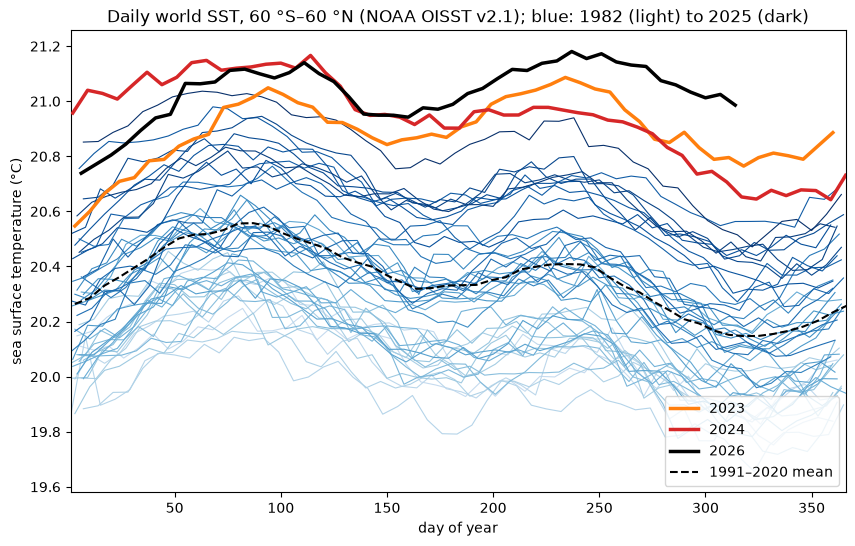

In [4]:
df = world.to_dataframe(name="sst")
df["year"], df["doy"] = df.index.year, df.index.day_of_year
this_year = df.year.max()
years = range(1982, this_year + 1)               # 1981 starts in September: skip it
highlight = {2023: "tab:orange", 2024: "tab:red", this_year: "k"}

fig, ax = plt.subplots(figsize=(10, 6))
cmap = plt.cm.Blues
for y in years:
    one = df[df.year == y]
    if y in highlight:
        ax.plot(one.doy, one.sst, color=highlight[y], lw=2.5, label=str(y), zorder=3)
    else:
        ax.plot(one.doy, one.sst, color=cmap(0.25 + 0.75 * (y - 1982) / (this_year - 1 - 1982)), lw=0.8)
base = df[(df.year >= 1991) & (df.year <= 2020)]
clim = base.groupby(base.doy // 7 * 7 + 3).sst.mean()   # mean by week of the year
ax.plot(clim.index, clim, "k--", lw=1.5, label="1991–2020 mean")
ax.set(xlabel="day of year", ylabel="sea surface temperature (°C)", xlim=(1, 366),
       title=f"Daily world SST, 60 °S–60 °N (NOAA OISST v2.1); blue: 1982 (light) to {this_year - 1} (dark)")
ax.legend(loc="lower right")
plt.show()

Each line is one year. The blue lines climb steadily: years in the 1980s average about
20.05 °C, the 2010s about 20.5 °C. In 2023 (orange) the ocean jumped above every earlier year, and
it has stayed there: 2023 through 2026 each average about 0.5–0.65 °C above the 1991–2020 mean.
2026 (black, through mid-November) is running warmest of all. Reading every day (`step = 1`)
finds the warmest day in the record so far: 21.18 °C on 26 August 2026.

This is the chart [Climate Reanalyzer](https://climatereanalyzer.org/clim/sst_daily/) publishes,
from the same OISST v2.1 data, rebuilt here from 16,500 files with one `mean()`.

**More:** the store's `monthly/` group holds monthly means already computed and chunked for long
time series, which is far cheaper when monthly is enough; see the
[store's README](https://github.com/ocean-icechunks/noaa_oisst).